In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
!unzip -q /content/drive/MyDrive/data.zip -d /content/


In [5]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

from weights import get_inverse_log_weights
from config import CLASS_LABELS

class_weights = get_inverse_log_weights(device)

print("\nClass Weights:")
for label, w in zip(CLASS_LABELS, class_weights):
    print(f"{label:15s} : {w.item():.4f}")



Class Weights:
Trees           : 1.0581
Lush Bushes     : 1.0581
Dry Grass       : 1.0581
Dry Bushes      : 1.0581
Ground Clutter  : 1.0581
Flower          : 1.0581
Logs            : 1.0581
Rocks           : 1.0581
Landscape       : 0.9018
Sky             : 0.6338


In [7]:
# Install required packages
!pip install segmentation-models-pytorch
!pip install albumentations
!pip install tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.7 MB/s eta 0:00:00


In [8]:
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

from dataset import OffroadDataset
from model import get_model
from loss import CombinedLoss
from weights import get_inverse_log_weights

from utils import calculate_iou_dataset
from config import *

In [9]:
torch.backends.cudnn.benchmark = True


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [ ]:
import torch
from torch.utils.data import Subset

# ================= DATA (LIMITED FOR TESTING) =================
# Create full datasets as before
train_dataset = OffroadDataset(
    TRAIN_IMG_DIR,
    TRAIN_MASK_DIR,
    is_train_dataset=True,
    perform_augmentation=True
)

val_dataset = OffroadDataset(
    VAL_IMG_DIR,
    VAL_MASK_DIR,
    is_train_dataset=False,
    perform_augmentation=False
)


# Now create DataLoaders using the subsets
train_loader = DataLoader(
    train_dataset,                    
    batch_size=BATCH_SIZE,            
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,                     
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [18]:
model = get_model().to(device)

In [19]:
print(model)

DeepLabV3Plus(
  (encoder): EfficientNetEncoder(
    (_conv_stem): Conv2dStaticSamePadding(
      3, 40, kernel_size=(3, 3), stride=(2, 2), bias=False
      (static_padding): ZeroPad2d((0, 1, 0, 1))
    )
    (_bn0): BatchNorm2d(40, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
    (_blocks): ModuleList(
      (0): MBConvBlock(
        (_expand_conv): Identity()
        (_bn0): Identity()
        (_depthwise_conv): Conv2dStaticSamePadding(
          40, 40, kernel_size=(3, 3), stride=[1, 1], groups=40, bias=False
          (static_padding): ZeroPad2d((1, 1, 1, 1))
        )
        (_bn1): BatchNorm2d(40, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
        (_se_reduce): Conv2dStaticSamePadding(
          40, 10, kernel_size=(1, 1), stride=(1, 1)
          (static_padding): Identity()
        )
        (_se_expand): Conv2dStaticSamePadding(
          10, 40, kernel_size=(1, 1), stride=(1, 1)
          (static_paddin

In [20]:
class_weights=get_inverse_log_weights(device)

In [21]:
criterion = CombinedLoss(
    class_weights=class_weights,
    weight_ce=1.0,
    weight_dice=1.0
)

In [22]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)


In [ ]:

scaler = torch.amp.GradScaler()

best_miou = 0.0

# ================= TRAIN LOOP =================
for epoch in range(EPOCHS):

    print(f"\n===== Epoch {epoch+1}/{EPOCHS} =====")

    # -------- TRAIN --------
    model.train()
    train_loss = 0.0

    train_bar = tqdm(train_loader, desc="Training")

    for images, masks in train_bar:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        with torch.amp.autocast(device_type="cuda"):
            outputs = model(images)
            loss = criterion(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss /= len(train_loader)

    print(f"\nTrain Loss: {train_loss:.4f}")

    # -------- VALIDATION --------
    iou_per_class, mean_iou = calculate_iou_dataset(
        model,
        val_loader,
        NUM_CLASSES,
        device
    )

    print("\nPer-Class IoU:")
    for label, iou in zip(CLASS_LABELS, iou_per_class):
        print(f"{label:15s}: {iou.item():.4f}")

    print(f"\nMean IoU: {mean_iou.item():.4f}")

    scheduler.step()

    print(f"Learning Rate: {scheduler.get_last_lr()[0]:.6f}")

    # -------- SAVE BEST --------
    if mean_iou > best_miou:
        best_miou = mean_iou
        torch.save(model.state_dict(), "best_model.pth")
        print(" Best model saved!")

print("\nTraining Complete.")


===== Epoch 1/40 =====


Training: 100%|██████████| 547/547 [04:38<00:00,  1.96it/s, loss=1.0543]


Train Loss: 1.3522



Per-Class IoU:
Trees          : 0.7513
Lush Bushes    : 0.5799
Dry Grass      : 0.6268
Dry Bushes     : 0.3776
Ground Clutter : 0.2227
Flower         : 0.4396
Logs           : 0.0000
Rocks          : 0.2436
Landscape      : 0.5237
Sky            : 0.8953

Mean IoU: 0.4661
Learning Rate: 0.000100
🔥 Best model saved!

===== Epoch 2/40 =====


Training: 100%|██████████| 547/547 [03:40<00:00,  2.48it/s, loss=0.9691]


Train Loss: 0.9479


... (62 outputs left out)


Train Loss: 0.6317



Per-Class IoU:
Trees          : 0.7951
Lush Bushes    : 0.6779
Dry Grass      : 0.6988
Dry Bushes     : 0.5103
Ground Clutter : 0.3922
Flower         : 0.5067
Logs           : 0.3472
Rocks          : 0.4903
Landscape      : 0.5761
Sky            : 0.8926

Mean IoU: 0.5887
Learning Rate: 0.000038

===== Epoch 24/40 =====


Training:  23%|██▎       | 127/547 [00:52<02:53,  2.42it/s, loss=0.7858]


KeyboardInterrupt: 

In [24]:
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

from dataset import OffroadDataset
from model import get_model
from utils import calculate_iou_dataset
from config import *

# ================= DEVICE =================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ================= LOAD TEST DATA =================
test_dataset = OffroadDataset(
    TEST_IMG_DIR,
    TEST_MASK_DIR,
    is_train_dataset=False,
    perform_augmentation=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ================= LOAD MODEL =================
model = get_model().to(device)

model.load_state_dict(torch.load("/content/best_model.pth", map_location=device))
model.eval()

print("Model loaded successfully.")

# ================= EVALUATE =================
iou_per_class, mean_iou = calculate_iou_dataset(
    model,
    test_loader,
    NUM_CLASSES,
    device
)

print("\nTest Per-Class IoU:")
for label, iou in zip(CLASS_LABELS, iou_per_class):
    print(f"{label:15s}: {iou.item():.4f}")

print(f"\nTest Mean IoU: {mean_iou.item():.4f}")


Using device: cuda
Model loaded successfully.

Test Per-Class IoU:
Trees          : 0.2865
Lush Bushes    : 0.0003
Dry Grass      : 0.4789
Dry Bushes     : 0.4416
Ground Clutter : 0.0000
Flower         : 0.0000
Logs           : 0.0000
Rocks          : 0.0496
Landscape      : 0.6753
Sky            : 0.9796

Test Mean IoU: 0.2912


Model loaded.
Showing sample index: 510


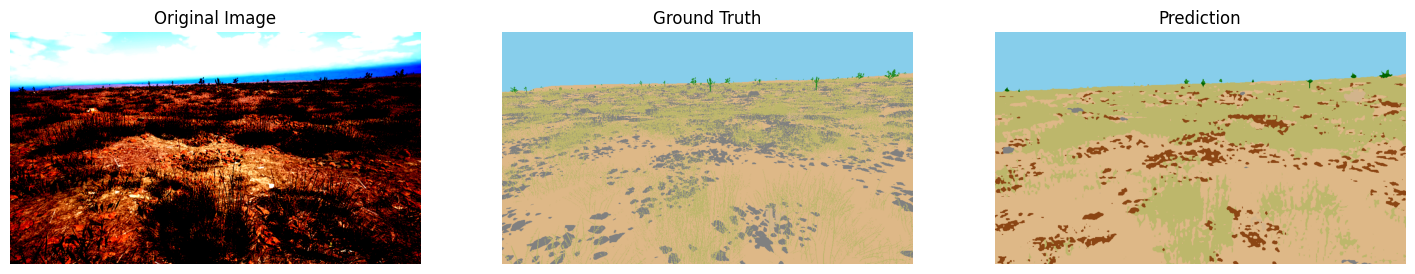

In [35]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import random

from dataset import OffroadDataset
from model import get_model
from config import *

# ================= DEVICE =================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ================= LOAD MODEL =================
model = get_model().to(device)
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()

print("Model loaded.")

# ================= LOAD TEST DATA =================
test_dataset = OffroadDataset(
    TEST_IMG_DIR,
    TEST_MASK_DIR,
    is_train_dataset=False,
    perform_augmentation=False
)

# ================= PICK RANDOM SAMPLE =================
idx = random.randint(0, len(test_dataset) - 1)
image, mask = test_dataset[idx]

print(f"Showing sample index: {idx}")

image_tensor = image.unsqueeze(0).to(device)

# ================= INFERENCE =================
with torch.no_grad():
    output = model(image_tensor)
    pred = torch.argmax(output, dim=1).squeeze(0).cpu().numpy()

# Convert image for display
image_np = image.permute(1, 2, 0).numpy()
mask_np = mask.numpy()

# ================= COLOR MAP =================
COLORS = np.array([
    [34,139,34],     # Trees
    [0,100,0],       # Lush Bushes
    [189,183,107],   # Dry Grass
    [210,180,140],   # Dry Bushes
    [139,69,19],     # Ground Clutter
    [255,0,255],     # Flower
    [160,82,45],     # Logs
    [128,128,128],   # Rocks
    [222,184,135],   # Landscape
    [135,206,235],   # Sky
])

pred_color = COLORS[pred]
mask_color = COLORS[mask_np]

# ================= PLOT =================
plt.figure(figsize=(18,6))

plt.subplot(1,3,1)
plt.imshow(image_np)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(mask_color)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(pred_color)
plt.title("Prediction")
plt.axis("off")

plt.show()


Model loaded.
Showing sample index: 246


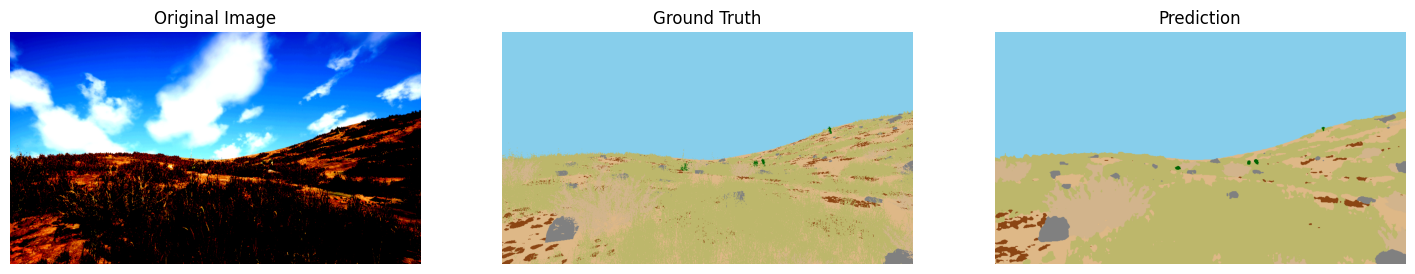

In [31]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import random

from dataset import OffroadDataset
from model import get_model
from config import *

# ================= DEVICE =================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ================= LOAD MODEL =================
model = get_model().to(device)
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()

print("Model loaded.")

# ================= LOAD TEST DATA =================
# test_dataset = OffroadDataset(
#     TEST_IMG_DIR,
#     TEST_MASK_DIR,
#     is_train_dataset=False,
#     perform_augmentation=False
# )

# ================= PICK RANDOM SAMPLE =================
idx = random.randint(0, len(test_dataset) - 1)
image, mask = train_dataset[idx]

print(f"Showing sample index: {idx}")

image_tensor = image.unsqueeze(0).to(device)

# ================= INFERENCE =================
with torch.no_grad():
    output = model(image_tensor)
    pred = torch.argmax(output, dim=1).squeeze(0).cpu().numpy()

# Convert image for display
image_np = image.permute(1, 2, 0).numpy()
mask_np = mask.numpy()

# ================= COLOR MAP =================
COLORS = np.array([
    [34,139,34],     # Trees
    [0,100,0],       # Lush Bushes
    [189,183,107],   # Dry Grass
    [210,180,140],   # Dry Bushes
    [139,69,19],     # Ground Clutter
    [255,0,255],     # Flower
    [160,82,45],     # Logs
    [128,128,128],   # Rocks
    [222,184,135],   # Landscape
    [135,206,235],   # Sky
])

pred_color = COLORS[pred]
mask_color = COLORS[mask_np]

# ================= PLOT =================
plt.figure(figsize=(18,6))

plt.subplot(1,3,1)
plt.imshow(image_np)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(mask_color)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(pred_color)
plt.title("Prediction")
plt.axis("off")












plt.show()


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import random

from dataset import OffroadDataset
from config import *

# Load dataset WITH augmentation enabled
aug_dataset = OffroadDataset(
    TRAIN_IMG_DIR,
    TRAIN_MASK_DIR,
    is_train_dataset=True,
    perform_augmentation=True
)

# Load dataset WITHOUT augmentation
clean_dataset = OffroadDataset(
    TRAIN_IMG_DIR,
    TRAIN_MASK_DIR,
    is_train_dataset=False,
    perform_augmentation=False
)

# Pick random index
idx = random.randint(0, len(clean_dataset) - 1)

print(f"Inspecting index: {idx}")

# Get original
orig_img, orig_mask = clean_dataset[idx]

# Get augmented version
aug_img, aug_mask = aug_dataset[idx]

# Convert for display
orig_img_np = orig_img.permute(1,2,0).numpy()
aug_img_np = aug_img.permute(1,2,0).numpy()

orig_mask_np = orig_mask.numpy()
aug_mask_np = aug_mask.numpy()

# Plot
plt.figure(figsize=(18,6))

plt.subplot(1,4,1)
plt.imshow(orig_img_np)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(aug_img_np)
plt.title("Augmented Image")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(orig_mask_np, cmap="jet")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(aug_mask_np, cmap="jet")
plt.title("Augmented Mask")
plt.axis("off")

plt.show()


ModuleNotFoundError: No module named 'albumentations'


⏱️ Cell executed in: 6.399 sec


In [2]:
!pip install opencv-python

     --------------------------------------- 40.2/40.2 MB 13.4 MB/s eta 0:00:00
  Using cached numpy-2.2.6-cp310-cp310-win_amd64.whl (12.9 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4

⏱️ Cell executed in: 19.216 sec


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'D:\\python_envs\\torch\\torch_gpu\\Lib\\site-packages\\~umpy.libs\\libopenblas64__v0.3.23-293-gc2f4bdbb-gcc_10_3_0-2bde3a66a51006b2b53eb373ff767a3f.dll'
Check the permissions.

You should consider upgrading via the 'D:\python_envs\torch\torch_gpu\Scripts\python.exe -m pip install --upgrade pip' command.
